# лабораторная работа 2

## полносвязная нейронная сеть

в работе используется двухслойная полносвязная нейронная сеть для классификации изображений cifar 10. первый полносвязный слой использует relu, а на выходе применяется softmax.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scripts.classifiers.neural_net import TwoLayerNet
from scripts.data_utils import load_CIFAR10

%matplotlib inline

plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

np.random.seed(42)

def rel_error(x, y):
    return np.max(np.abs(x - y) / np.maximum(1e-8, np.abs(x) + np.abs(y)))

## проверка сети на модельных данных

In [2]:
input_size = 4
hidden_size = 10
num_classes = 3
num_inputs = 5

def init_toy_model():
    np.random.seed(0)
    return TwoLayerNet(input_size, hidden_size, num_classes, std=1e-1)

def init_toy_data():
    np.random.seed(1)
    X = 10 * np.random.randn(num_inputs, input_size)
    y = np.array([0, 1, 2, 2, 1])
    return X, y

net = init_toy_model()
X, y = init_toy_data()

### прямой проход

In [3]:
scores = net.loss(X)

correct_scores = np.asarray([
    [-0.81233741, -1.27654624, -0.70335995],
    [-0.17129677, -1.18803311, -0.47310444],
    [-0.51590475, -1.01354314, -0.85042150],
    [-0.15419291, -0.48629638, -0.52901952],
    [-0.00618733, -0.12435261, -0.15226949]
])

difference = np.sum(np.abs(scores - correct_scores))

print('полученные оценки')
print(scores)
print()
print('эталонные оценки')
print(correct_scores)
print()
print('разница', difference)

полученные оценки
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

эталонные оценки
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

разница 3.6802720745909845e-08


### проверка функции потерь

In [4]:
loss, _ = net.loss(X, y, reg=0.05)
correct_loss = 1.30378789133
loss_difference = np.abs(loss - correct_loss)

print('полученный loss', loss)
print('разница', loss_difference)

полученный loss 1.3037878913298202
разница 1.7985612998927536e-13


### проверка обратного прохода

In [5]:
from scripts.gradient_check import eval_numerical_gradient

loss, grads = net.loss(X, y, reg=0.05)

for param_name in grads:
    f = lambda W: net.loss(X, y, reg=0.05)[0]
    grad_num = eval_numerical_gradient(
        f,
        net.params[param_name],
        verbose=False
    )
    error = rel_error(grad_num, grads[param_name])
    print(param_name, 'max relative error', error)

W2 max relative error 3.440707836450643e-09
b2 max relative error 4.447625061840524e-11
W1 max relative error 3.5613181785044393e-09
b1 max relative error 2.738421249546978e-09


### обучение на модельных данных

final training loss 0.005063005847181078


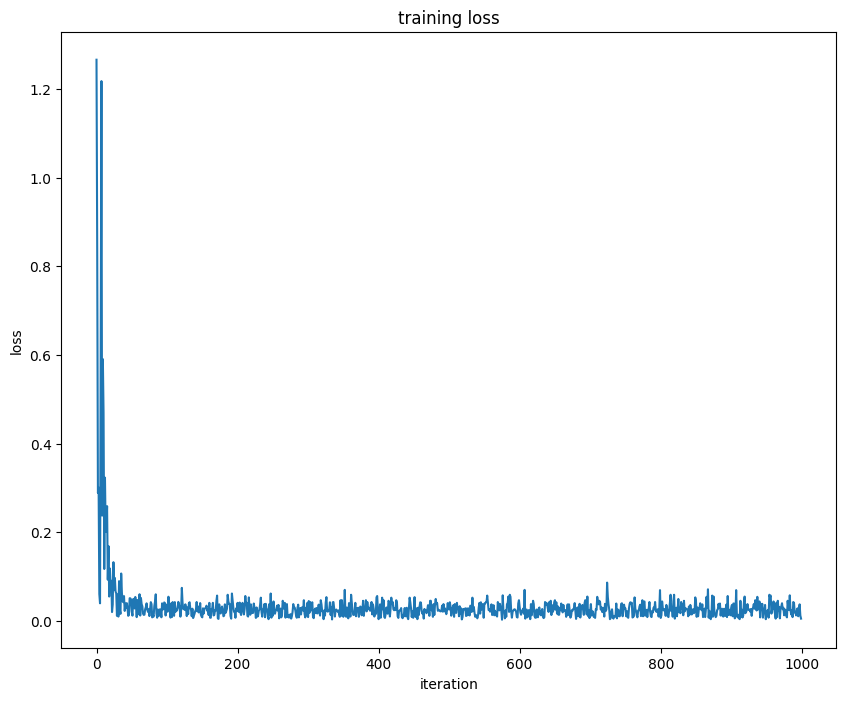

In [6]:
net = init_toy_model()

stats_toy = net.train(
    X,
    y,
    X,
    y,
    learning_rate=1e-1,
    reg=5e-6,
    num_iters=1000,
    batch_size=5,
    verbose=False
)

print('final training loss', stats_toy['loss_history'][-1])

plt.plot(stats_toy['loss_history'])
plt.xlabel('iteration')
plt.ylabel('loss')
plt.title('training loss')
plt.show()

## подготовка cifar 10

In [7]:
cifar10_dir = 'scripts/datasets/cifar-10-batches-py'

X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

num_training = 49000
num_validation = 1000
num_test = 1000

X_val = X_train[num_training:num_training + num_validation]
y_val = y_train[num_training:num_training + num_validation]

X_train = X_train[:num_training]
y_train = y_train[:num_training]

X_test = X_test[:num_test]
y_test = y_test[:num_test]

X_train = X_train.reshape(X_train.shape[0], -1)
X_val = X_val.reshape(X_val.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

mean_image = np.mean(X_train, axis=0)

X_train -= mean_image
X_val -= mean_image
X_test -= mean_image

print('train shape', X_train.shape)
print('validation shape', X_val.shape)
print('test shape', X_test.shape)

train shape (49000, 3072)
validation shape (1000, 3072)
test shape (1000, 3072)


## обучение сети с исходными параметрами

In [8]:
input_size = X_train.shape[1]
hidden_size = 50
num_classes = 10

net = TwoLayerNet(input_size, hidden_size, num_classes)

stats = net.train(
    X_train,
    y_train,
    X_val,
    y_val,
    num_iters=1000,
    batch_size=200,
    learning_rate=1e-4,
    learning_rate_decay=0.95,
    reg=0.25,
    verbose=True
)

val_acc = np.mean(net.predict(X_val) == y_val)

print('validation accuracy', val_acc)

iteration 0 of 1000 loss 2.3029494256507803
iteration 100 of 1000 loss 2.302446927676467
iteration 200 of 1000 loss 2.298419448659121
iteration 300 of 1000 loss 2.268032593541576
iteration 400 of 1000 loss 2.180453471808111
iteration 500 of 1000 loss 2.1512297589323577
iteration 600 of 1000 loss 2.0511014635125715
iteration 700 of 1000 loss 2.060470128813087
iteration 800 of 1000 loss 1.907509729727839
iteration 900 of 1000 loss 1.9711842483247994
validation accuracy 0.291


## настройка гиперпараметров

In [9]:
settings = [
    (50, 1e-4, 0.25),
    (50, 5e-4, 0.25),
    (100, 5e-4, 0.10),
    (100, 8e-4, 0.25)
]

best_val = 0
best_params = None

for hidden_size, learning_rate, reg in settings:
    model = TwoLayerNet(input_size, hidden_size, num_classes)

    model.train(
        X_train,
        y_train,
        X_val,
        y_val,
        num_iters=600,
        batch_size=200,
        learning_rate=learning_rate,
        learning_rate_decay=0.95,
        reg=reg,
        verbose=False
    )

    val_acc = np.mean(model.predict(X_val) == y_val)

    print(
        'hidden', hidden_size,
        'learning rate', learning_rate,
        'reg', reg,
        'validation accuracy', val_acc
    )

    if val_acc > best_val:
        best_val = val_acc
        best_params = (hidden_size, learning_rate, reg)

print()
print('best validation accuracy', best_val)
print('best hidden size', best_params[0])
print('best learning rate', best_params[1])
print('best reg', best_params[2])

hidden 50 learning rate 0.0001 reg 0.25 validation accuracy 0.243
hidden 50 learning rate 0.0005 reg 0.25 validation accuracy 0.396
hidden 100 learning rate 0.0005 reg 0.1 validation accuracy 0.406
hidden 100 learning rate 0.0008 reg 0.25 validation accuracy 0.451

best validation accuracy 0.451
best hidden size 100
best learning rate 0.0008
best reg 0.25


## обучение лучшей модели

In [10]:
best_hidden, best_lr, best_reg = best_params

best_net = TwoLayerNet(input_size, best_hidden, num_classes)

best_stats = best_net.train(
    X_train,
    y_train,
    X_val,
    y_val,
    num_iters=1500,
    batch_size=200,
    learning_rate=best_lr,
    learning_rate_decay=0.95,
    reg=best_reg,
    verbose=True
)

train_acc = np.mean(best_net.predict(X_train) == y_train)
val_acc = np.mean(best_net.predict(X_val) == y_val)
test_acc = np.mean(best_net.predict(X_test) == y_test)

print('train accuracy', train_acc)
print('validation accuracy', val_acc)
print('test accuracy', test_acc)

iteration 0 of 1500 loss 2.3033594728011586
iteration 100 of 1500 loss 1.9618914534036533
iteration 200 of 1500 loss 1.819122710616032
iteration 300 of 1500 loss 1.7448572366456183
iteration 400 of 1500 loss 1.6891524322055564
iteration 500 of 1500 loss 1.6766260689761547
iteration 600 of 1500 loss 1.645568225712867
iteration 700 of 1500 loss 1.549513697147564
iteration 800 of 1500 loss 1.5480891799171042
iteration 900 of 1500 loss 1.499667929690724
iteration 1000 of 1500 loss 1.5491433563228938
iteration 1100 of 1500 loss 1.4451943250367503
iteration 1200 of 1500 loss 1.443862385149484
iteration 1300 of 1500 loss 1.405626862491631
iteration 1400 of 1500 loss 1.5687580411657072
train accuracy 0.5146122448979592
validation accuracy 0.496
test accuracy 0.512


## графики обучения

по графикам можно посмотреть изменение функции потерь и точности во время обучения.


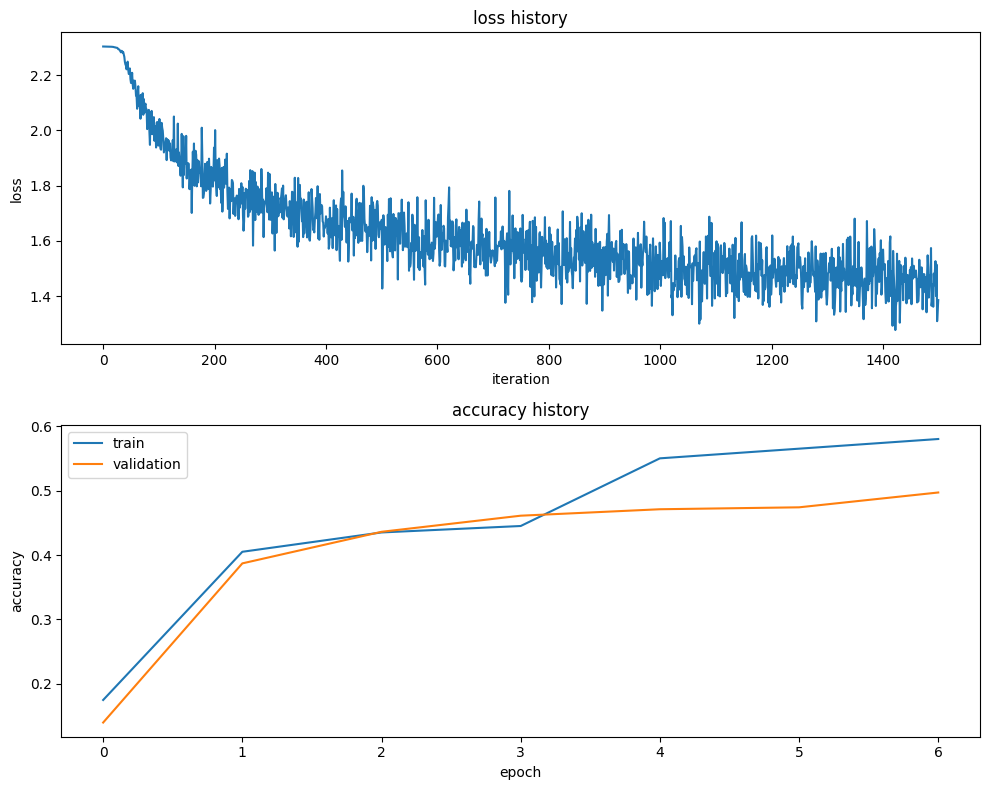

In [11]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)
plt.plot(best_stats['loss_history'])
plt.title('loss history')
plt.xlabel('iteration')
plt.ylabel('loss')

plt.subplot(2, 1, 2)
plt.plot(best_stats['train_acc_history'], label='train')
plt.plot(best_stats['val_acc_history'], label='validation')
plt.title('accuracy history')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()

plt.tight_layout()
plt.show()

## визуализация весов первого слоя

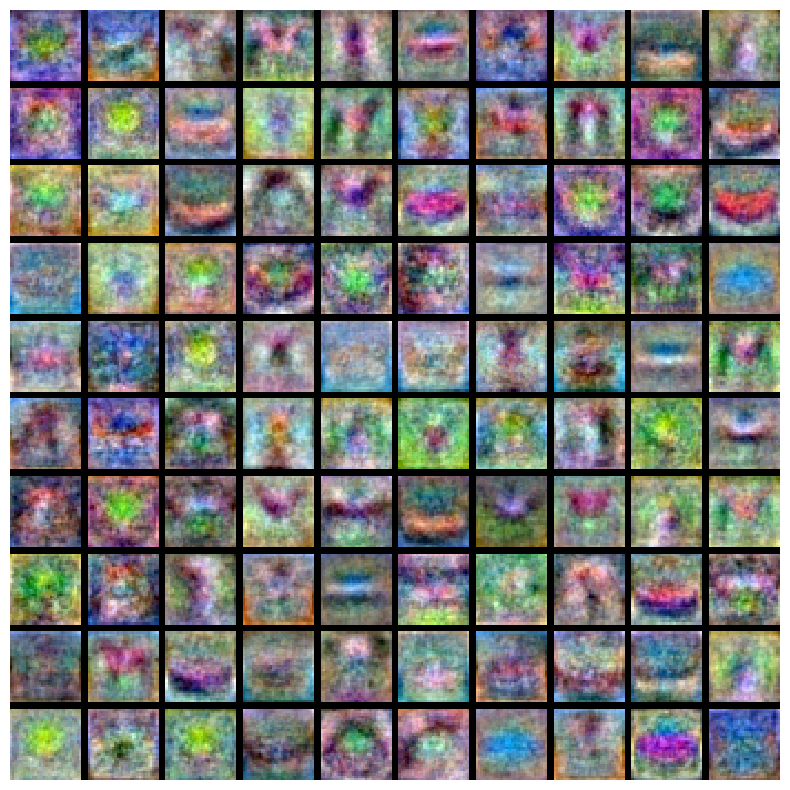

In [12]:
from scripts.vis_utils import visualize_grid

def show_net_weights(net):
    W1 = net.params['W1']
    W1 = W1.reshape(32, 32, 3, -1).transpose(3, 0, 1, 2)

    plt.figure(figsize=(10, 10))
    plt.imshow(visualize_grid(W1, padding=3).astype('uint8'))
    plt.axis('off')
    plt.show()

show_net_weights(best_net)